In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
import pandas as pd

Caso1, Caso2, Caso3 = pd.read_excel('Trabajo Final - Hoja de Datos.xlsx', sheet_name= 'Caso1'), pd.read_excel('Trabajo Final - Hoja de Datos.xlsx', sheet_name= 'Caso2'), pd.read_excel('Trabajo Final - Hoja de Datos.xlsx', sheet_name= 'Caso3')

: 

# Caso 1



a)Graficar

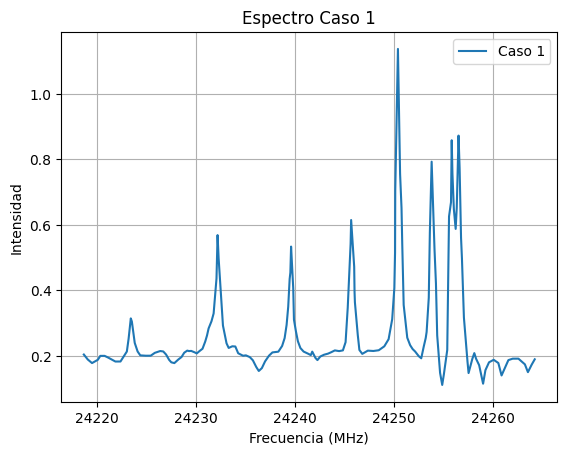

In [ ]:
plt.plot(Caso1['Nu(MHz)'], Caso1['Intensidad'], label='Caso 1')
plt.xlabel('Frecuencia (MHz)')
plt.ylabel('Intensidad')

plt.legend()
plt.grid(True)
plt.show()

b) Rotular picos

In [ ]:
Picos = sp.signal.find_peaks(Caso1['Intensidad'], height=0.23)

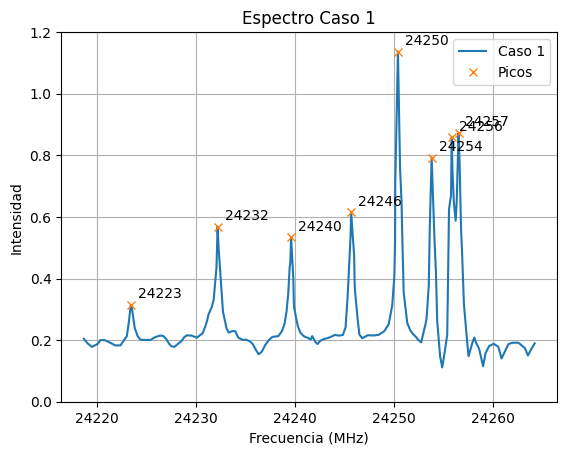

In [ ]:
plt.plot(Caso1['Nu(MHz)'], Caso1['Intensidad'], label='Caso 1')
plt.plot(Caso1['Nu(MHz)'][Picos[0]], Caso1['Intensidad'][Picos[0]], "x", label='Picos')
for i in range(Picos[0].size):
    x = Caso1['Nu(MHz)'][Picos[0][i]]
    y = Caso1['Intensidad'][Picos[0][i]]
    plt.annotate(str(f'{x:.0f}'), (x, y), xytext=(5, 5), textcoords='offset points')
plt.xlabel('Frecuencia (MHz)')
plt.ylabel('Intensidad')
plt.title('Espectro Caso 1')
plt.legend()
plt.grid(True)
plt.ylim(0, 1.2)
plt.show()

,K,K^2,Centro(MHz),FWHM
0,0,0,24256.58325,0.489673
1,1,1,24255.88159,0.489673
2,2,4,24253.87337,0.489673
3,3,9,24250.46770,0.489673
4,4,16,24245.78529,0.489673
5,5,25,24239.64929,0.489673
6,6,36,24232.25112,0.489673
7,7,49,24223.49072,0.489673


-0.6753027470799455 24256.565589323898 0.9999985953106507


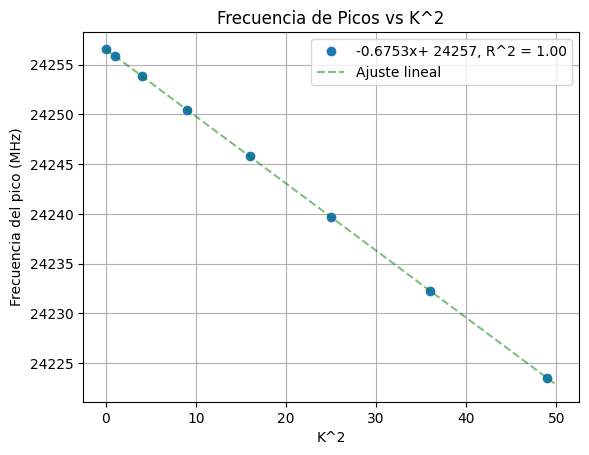

In [ ]:
Tabla = pd.read_csv('Tabla posiciones y FWHM Caso1.csv', sep = ';', decimal= ',').sort_values(by = ["Centro(MHz)"], ascending=False)

display(Tabla)
Picos = np.arange(0,Tabla.shape[0],1)**2

result = sp.stats.linregress(Picos, Tabla["Centro(MHz)"])
m, b, R2 = result.slope, result.intercept, np.abs(result.rvalue)
print(m,b,R2)

x = np.linspace(0,50,100)
plt.plot(Picos, Tabla["Centro(MHz)"], 'o', label = f'{m:.4f}x+ {b:.0f}, R^2 = {R2:.2f}')
plt.plot(x, m*x + b, '--' ,alpha = 0.5, color = 'green', label = "Ajuste lineal")
plt.grid(True)
plt.title("Frecuencia de Picos vs K^2")
plt.ylabel("Frecuencia del pico (MHz)")
plt.xlabel("K^2")
plt.legend()
plt.show()




Dada la ecuacion:
$$
v_0 - 2D_{JK}(J+1)K^2
$$
y dado que la transicion rotacional del Isotiocianato de Silano es $J = 8 \leftarrow 7$.
$$
\Rightarrow v_0 - 16D_{JK}K^2
$$
Dada la ecuacion lineal que obtuvimos anteriormente cuando $ K = 7 $

$$
\Rightarrow D_{JK} = \frac{m}{16}
$$
o la pendiente obtenida entre 16


In [ ]:
D_JK = -m/16
print(D_JK)

0.042206421692496596


$$
\Rightarrow D_{JK} \approx 0.0422 MHz
$$

# Caso 2

### a) Gráfica

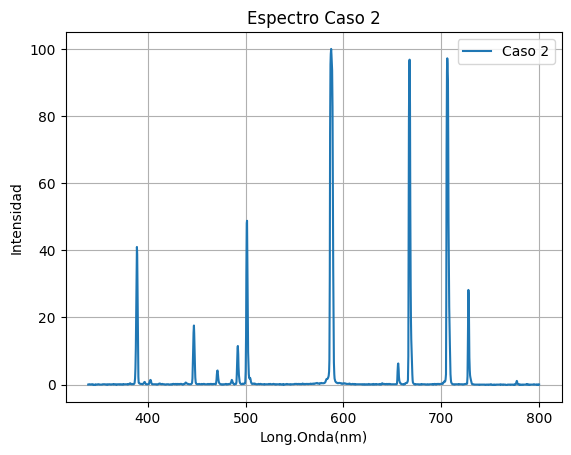

In [ ]:
plt.plot(Caso2['Long.Onda(nm)'], Caso2['Intensidad'], label='Caso 2')
plt.xlabel('Long.Onda(nm)')
plt.ylabel('Intensidad')
plt.title('Espectro Caso 2')
plt.legend()
plt.grid(True)
plt.show()

### b) Rotular picos

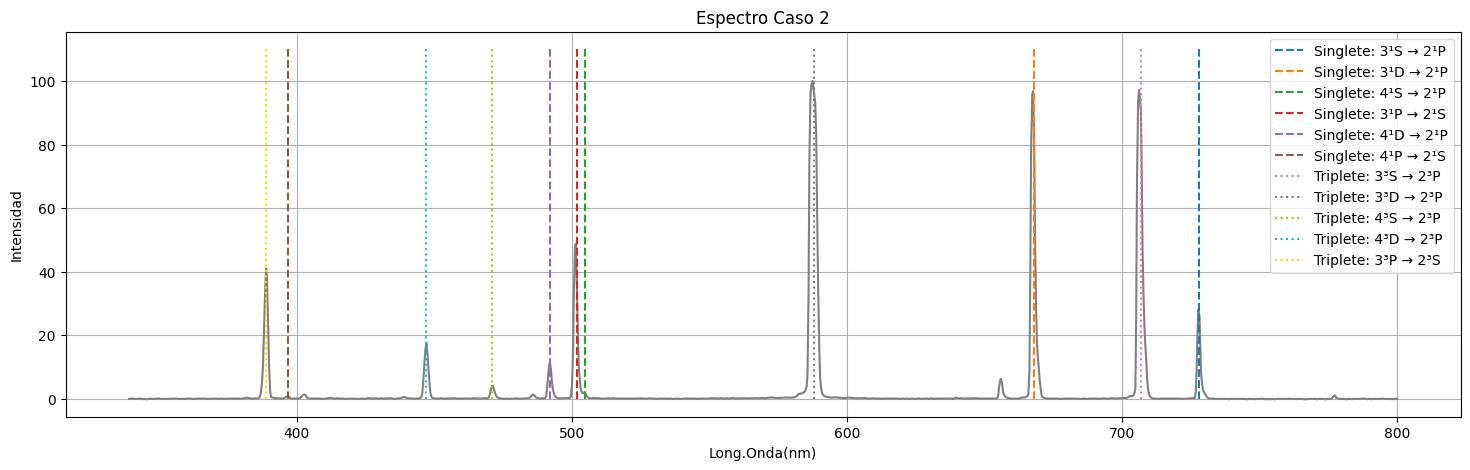

In [ ]:
# Sistema singlete
singlete_longitudes = [728, 668, 505, 502, 492, 397]  # nm
singlete_transiciones = [
    "3¹S → 2¹P",
    "3¹D → 2¹P",
    "4¹S → 2¹P",
    "3¹P → 2¹S",
    "4¹D → 2¹P",
    "4¹P → 2¹S",
]

# Sistema triplete
triplete_longitudes = [707, 588, 471, 447, 389]  # nm
triplete_transiciones = [
    "3³S → 2³P",
    "3³D → 2³P",
    "4³S → 2³P",
    "4³D → 2³P",
    "3³P → 2³S",
]

colores = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
    "tab:brown",
    "tab:pink",
    "tab:gray",
    "tab:olive",
    "tab:cyan",
    "gold",
]
plt.figure(figsize=(18,5))
plt.plot(Caso2['Long.Onda(nm)'], Caso2['Intensidad'], color='grey')
plt.xlabel('Long.Onda(nm)')
plt.ylabel('Intensidad')
plt.title('Espectro Caso 2')
for i in range(len(singlete_longitudes)):
    plt.vlines(singlete_longitudes[i], 0, 110, label='Singlete: '+singlete_transiciones[i], color=colores[i], linestyle='dashed')
for j in range(len(triplete_longitudes)):
    plt.vlines(triplete_longitudes[j], 0, 110, label='Triplete: '+triplete_transiciones[j], color=colores[6+j], linestyle='dotted')

plt.legend()
plt.grid(True)
plt.show()

### c) Predominancia de picos y homogeneidad de la muestra

Viendo la figura anterior, es aparente que tanto tripletes como singuletes aparecen en proporciones muy parecidas. Hay líneas débiles tanto en el singulete como en el triplete. Hay un par de líneas apreciables a simple vista que no corresponden con líneas de transición del He (como la cercana al singlete $3^1D\rightarrow2^1P$). Esto quiere decir que la muestra puede presentar impuresas de otros gases, aunque sean muy pocas.

### d) Tabla

Transición  Posición (nm)     Altura  FWHM (nm)
 3³P → 2³S        388.878  40.888900    1.58360
 4¹P → 2¹S        396.643   0.755336    1.90256
 4³D → 2³P        447.153  17.471600    1.67188
 4³S → 2³P        471.273   4.102640    1.68361
 4¹D → 2¹P        492.100  11.040800    1.58354
 3¹P → 2¹S        501.422  49.085800    1.39938
 4¹S → 2¹P        504.554   2.032730    1.76607
 3³D → 2³P        587.756 100.503000    2.17675
 3¹D → 2¹P        667.683 100.364000    1.58939
 3³S → 2³P        706.422 106.845000    1.98434
 3¹S → 2¹P        727.966  28.508500    1.26908


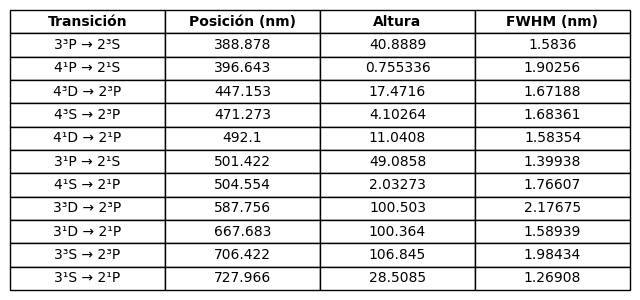

In [ ]:
df = pd.read_csv(
    "Caso2_picos.csv",
    sep=r"\s+",
    comment="#",
    header=None,
    names=["ID", "Type", "Center", "Height", "Area", "FWHM",
           "p_height", "p_center", "p_hwhm"],
    usecols=["Center", "Height", "FWHM"],
)

#print(df.loc[:,'Center'])

ids=['0','1','2','3','4','5','6','7','8','9','10']

ids[0]=triplete_transiciones[1]
ids[1]=triplete_transiciones[0]
ids[2]=singlete_transiciones[1]
ids[3]=singlete_transiciones[3]
ids[4]=triplete_transiciones[4]
ids[5]=singlete_transiciones[0]
ids[6]=triplete_transiciones[3]
ids[7]=singlete_transiciones[4]
ids[8]=singlete_transiciones[5]
ids[9]=triplete_transiciones[2]
ids[10]=singlete_transiciones[2]

tabla = pd.DataFrame({
    "Transición": ids,
    "Posición (nm)": df["Center"].to_numpy(),
    "Altura": df["Height"].to_numpy(),
    "FWHM (nm)": df["FWHM"].to_numpy(),
})
tabla = tabla.sort_values("Posición (nm)").reset_index(drop=True)


print(tabla.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
ax.axis("off")
t = ax.table(cellText=tabla.values, colLabels=tabla.columns,
             loc="center", cellLoc="center")
t.auto_set_font_size(False)
for j in range(len(tabla.columns)):
    t[0, j].set_text_props(fontweight="bold")
t.set_fontsize(10)
t.scale(1, 1.4)
#plt.savefig("tabla_picos.png", dpi=200, bbox_inches="tight")
plt.show()

### e) Tabla comparativa

In [ ]:
gro = pd.DataFrame({
    "Sistema": ["Singulete"] * len(singlete_longitudes) + ["Triplete"] * len(triplete_longitudes),
    "Transición": singlete_transiciones + triplete_transiciones,
    "Posición (Grotrian) (nm)": singlete_longitudes + triplete_longitudes,
})
gro = gro.sort_values("Posición (Grotrian) (nm)").reset_index(drop=True)
#print(gro.to_string(index=False))

tabla["Posición (Grotrian) (nm)"]=gro["Posición (Grotrian) (nm)"]

fityk = tabla["Posición (nm)"]
grotrian = tabla["Posición (Grotrian) (nm)"]

tabla["Error (%)"] = (100*(fityk - grotrian).abs() / grotrian).round(3)

print(tabla)

   Transición  Posición (nm)      Altura  FWHM (nm)  Posición (Grotrian) (nm)  \
0   3³P → 2³S        388.878   40.888900    1.58360                       389   
1   4¹P → 2¹S        396.643    0.755336    1.90256                       397   
2   4³D → 2³P        447.153   17.471600    1.67188                       447   
3   4³S → 2³P        471.273    4.102640    1.68361                       471   
4   4¹D → 2¹P        492.100   11.040800    1.58354                       492   
5   3¹P → 2¹S        501.422   49.085800    1.39938                       502   
6   4¹S → 2¹P        504.554    2.032730    1.76607                       505   
7   3³D → 2³P        587.756  100.503000    2.17675                       588   
8   3¹D → 2¹P        667.683  100.364000    1.58939                       668   
9   3³S → 2³P        706.422  106.845000    1.98434                       707   
10  3¹S → 2¹P        727.966   28.508500    1.26908                       728   

    Error (%)  
0       0.0

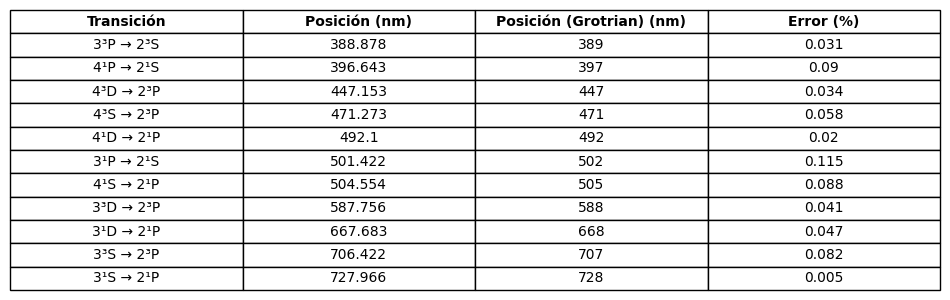

In [ ]:
cols_mostrar = ["Transición", "Posición (nm)", "Posición (Grotrian) (nm)", "Error (%)"]
t_vis = tabla[cols_mostrar]

fig, ax = plt.subplots(figsize=(12, 3))
ax.axis("off")
t = ax.table(cellText=t_vis.values, colLabels=t_vis.columns,
             loc="center", cellLoc="center")
t.auto_set_font_size(False)
for j in range(len(t_vis.columns)):
    t[0, j].set_text_props(fontweight="bold")
t.set_fontsize(10)
t.scale(1, 1.4)
plt.show()

Sí existe una muy buena aproximación.

# Caso 3

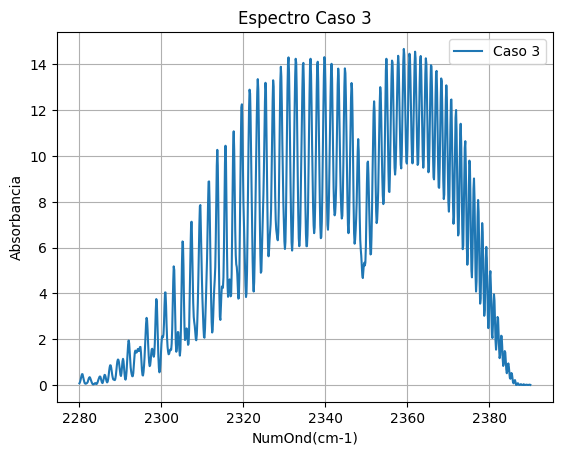

In [ ]:
plt.plot(Caso3['NumOnd(cm-1)'], Caso3['Absorbancia'], label='Caso 3')
plt.xlabel('NumOnd(cm-1)')
plt.ylabel('Absorbancia')
plt.title('Espectro Caso 3')
plt.legend()
plt.grid(True)
plt.show()